r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid


/tmp/ipykernel_1848075/2864816801.py:117: UserWarning: EEI_truth_4: TOA reference missing or invalid; plotting absolute errors without the relative-error axis.
  warnings.warn(
/tmp/ipykernel_1848075/2864816801.py:173: UserWarning: The figure layout has changed to tight
  fig_conv_earth.tight_layout(rect=(0, 0.06, 1, 0.95))


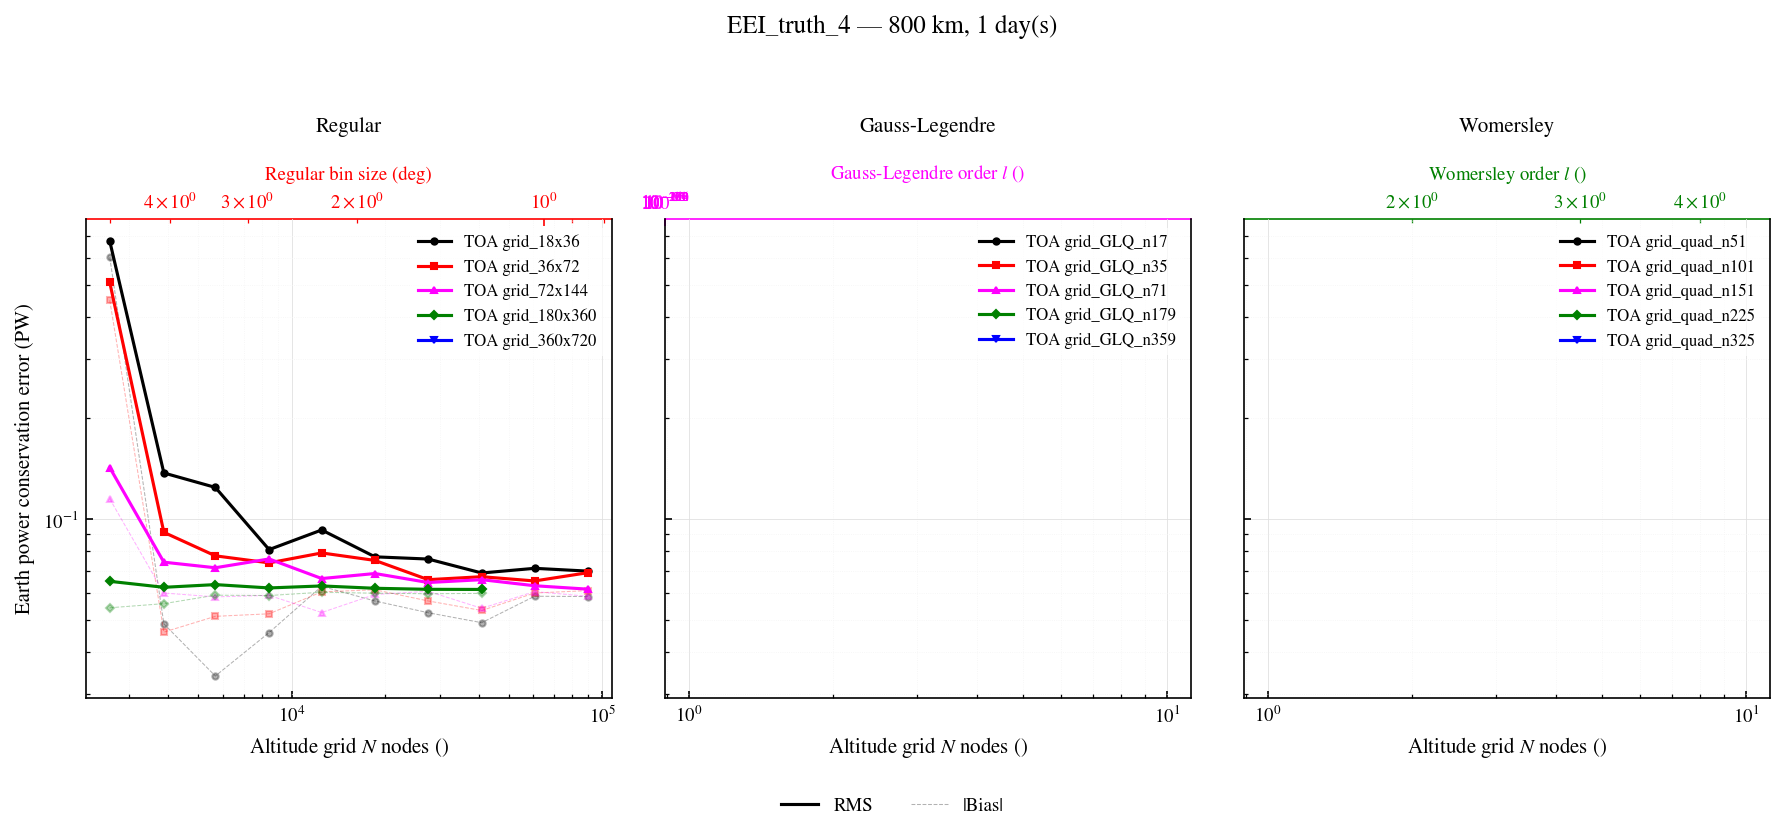

In [1]:
import os
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from SpaceBalls.radiation_fluxes_preprocessing import (
    get_toa_grid_from_rad_config, get_EEI_truth_daily_jd_arrays,
)
from SpaceBalls.radiation_settings import radiation_settings_from_EEI_truth_name
from SpaceBalls.sph_meshing import QuadratureGrid, RegularLatLonGrid
from SpaceBalls.plotter import Plotter
from SpaceBalls.paths import MEDIA_DIR

# Settings for this block; it can be run independently of the draft below.
EEI_names = ['EEI_truth_4']  # Add 'EEI_truth_4' if needed.
altitude_km = 800
n_days = 1
colors = ['k', 'red', 'magenta', 'green', 'blue']
markers = ['o', 's', '^', 'D', 'v']


def glq_n_to_l(n):
    return np.array(np.round(0.25 * (-3 + np.sqrt(1 + 8*n))), dtype=int)


def load_earth_history(EEI_name, filename, daily_jd_arrays):
    """Keep each day's time samples aligned, including when its file is missing."""
    histories = []
    for day_idx, day_jd_array in enumerate(daily_jd_arrays):
        path = os.path.join(MEDIA_DIR, 'conservation_convergence', EEI_name,
                            f'day_{day_idx}', filename)
        try:
            history = np.load(path)
        except FileNotFoundError:
            history = np.full(day_jd_array.shape, np.nan, dtype=float)
        histories.append(history)
    return np.concatenate(histories)


regular_altitude_grids = [
    RegularLatLonGrid(altitude_km, n_lat=int(np.round(180*f)),
                      n_lon=int(np.round(360*f)), flattening=0)
    for f in np.logspace(-0.7, 0.5, 15)
][:-5]
n_points_glq = np.logspace(
    np.log10(regular_altitude_grids[0].n_points),
    np.log10(regular_altitude_grids[-1].n_points), len(regular_altitude_grids)
)
glq_altitude_grids = [
    RegularLatLonGrid(altitude_km, lmax=int(l), quad_type='GLQ', flattening=0)
    for l in glq_n_to_l(n_points_glq)
]
womersley_altitude_grids = [
    QuadratureGrid(altitude_km, order=o, default_womersley=True, flattening=0)
    for o in np.arange(33, 325, 16)
]

def regular_nodes_to_bin_size(n):
    # Matplotlib may probe zero while locating ticks on the reciprocal axis.
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.sqrt(180*360 / np.asarray(n))


def regular_bin_size_to_nodes(d):
    with np.errstate(divide='ignore', invalid='ignore'):
        return 180*360 / np.asarray(d)**2


# Top-axis conversions and colors from plotting_grid_convergence.
top_axis_specs = [
    ('Regular bin size (deg)', 'red',
     (regular_nodes_to_bin_size, regular_bin_size_to_nodes)),
    ('Gauss-Legendre order $l$ ()', 'magenta',
     (lambda n: 0.25 * (-3 + np.sqrt(1 + 8*n)), lambda l: 2*l**2 + 3*l + 1)),
    ('Womersley order $l$ ()', 'green',
     (lambda n: np.sqrt(n / 0.5), lambda l: 0.5*l**2)),
]
style_handles = [
    Line2D([], [], color='k', linestyle='-', label='RMS'),
    Line2D([], [], color='k', linestyle='--', alpha=0.3, lw=0.5, label='|Bias|'),
]

# Surface integrals use km^2 with W/m^2; multiplying by 1e-9 gives PW.
integral_to_PW = 1e-9
conservation_figures = {}

for EEI_name in EEI_names:
    rad_config = radiation_settings_from_EEI_truth_name(EEI_name)
    daily_jd_arrays = get_EEI_truth_daily_jd_arrays(rad_config['jd_interval'])[:n_days]
    regular_toa_grids = [
        get_toa_grid_from_rad_config(rad_config, deg_bin_size=d)
        for d in (10, 5, 2.5, 1, 0.5)
    ]
    glq_toa_grids = [
        get_toa_grid_from_rad_config(rad_config, glq_order=l)
        for l in glq_n_to_l(np.array([grid.n_points for grid in regular_toa_grids]))
    ]
    womersley_toa_grids = [
        get_toa_grid_from_rad_config(rad_config, quadrature_order=int(l),
                                    default_womersley=True)
        for l in (51, 101, 151, 225, 325)
    ]
    all_grid_packs = [
        ('Regular', regular_toa_grids, regular_altitude_grids),
        ('Gauss-Legendre', glq_toa_grids, glq_altitude_grids),
        ('Womersley', womersley_toa_grids, womersley_altitude_grids),
    ]

    # One common reference for the shared absolute and relative y scales.
    reference_toa = load_earth_history(
        EEI_name, f'integrated_earth_toa_hist_{glq_toa_grids[-1].grid_name}.npy',
        daily_jd_arrays
    )
    reference_power = np.abs(np.mean(reference_toa)) * integral_to_PW
    has_reference = np.isfinite(reference_power) and reference_power > 0
    if not has_reference:
        warnings.warn(
            f'{EEI_name}: TOA reference missing or invalid; '
            'plotting absolute errors without the relative-error axis.'
        )

    fig_conv_earth, axes = plt.subplots(1, 3, figsize=(12, 5.5), sharey=True, layout="constrained")
    conservation_figures[EEI_name] = fig_conv_earth
    top_axes = []
    for ax, (grid_name, toa_grids, altitude_grids), top_spec in zip(
            axes, all_grid_packs, top_axis_specs):
        n_points_array = np.array([grid.n_points for grid in altitude_grids])
        for toa_idx, toa_grid in enumerate(toa_grids):
            toa_earth = load_earth_history(
                EEI_name, f'integrated_earth_toa_hist_{toa_grid.grid_name}.npy',
                daily_jd_arrays
            )
            bias_array, rms_array = [], []
            for altitude_grid in altitude_grids:
                earth = load_earth_history(
                    EEI_name,
                    f'integrated_earth_{altitude_km}_hist_{altitude_grid.grid_name}'
                    f'from_toa_{toa_grid.grid_name}.npy', daily_jd_arrays
                )
                error = earth - toa_earth # reference_toa # reference_toa #toa_earth
                bias_array.append(np.abs(np.mean(error)) * integral_to_PW)
                rms_array.append(np.max(np.abs(error)) * integral_to_PW) # np.sqrt(np.mean(error**2)) * integral_to_PW)

            style = dict(color=colors[toa_idx], marker=markers[toa_idx], markersize=3)
            ax.loglog(n_points_array, rms_array, '-',
                      label='TOA ' + toa_grid.grid_name, **style)
            ax.loglog(n_points_array, bias_array, '--', alpha=0.3, lw=0.5, **style)

        ax.set_title(grid_name, pad=42)
        ax.set_xlabel('Altitude grid $N$ nodes ()')
        ax.legend(fontsize=8)
        ax.spines['top'].set_visible(False)
        if has_reference:
            ax.axhline(1e-5 * reference_power, color='gray', lw=0.4, linestyle='--')
        Plotter.add_grid(ax, show_minor=True)
        top_label, top_color, transforms = top_spec
        ax_top = ax.secondary_xaxis('top', functions=transforms)
        ax_top.set_xlabel(top_label, color=top_color, fontsize=9, labelpad=6)
        ax_top.spines['top'].set_color(top_color)
        ax_top.tick_params(axis='x', colors=top_color, which='both')
        top_axes.append(ax_top)

    axes[0].set_ylabel('Earth power conservation error (PW)')
    if has_reference:
        ax_right = axes[-1].secondary_yaxis(
            'right', functions=(lambda x, ref=reference_power: x/ref,
                                lambda x, ref=reference_power: x*ref)
        )
        ax_right.set_ylabel('Relative error ()')
    fig_conv_earth.suptitle(f'{EEI_name} — {altitude_km} km, {n_days} day(s)', y=0.99)
    fig_conv_earth.legend(handles=style_handles, loc='lower center', ncol=2,
                          bbox_to_anchor=(0.5, 0))
    fig_conv_earth.tight_layout(rect=(0, 0.06, 1, 0.95))
    for ax_top in top_axes:
        Plotter.adjust_label_to_avoid_ticklabels(ax_top)
    plt.show()


r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid


/tmp/ipykernel_1848075/631778284.py:87: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig_earth, ax_earth = plt.subplots(figsize=(10,4))


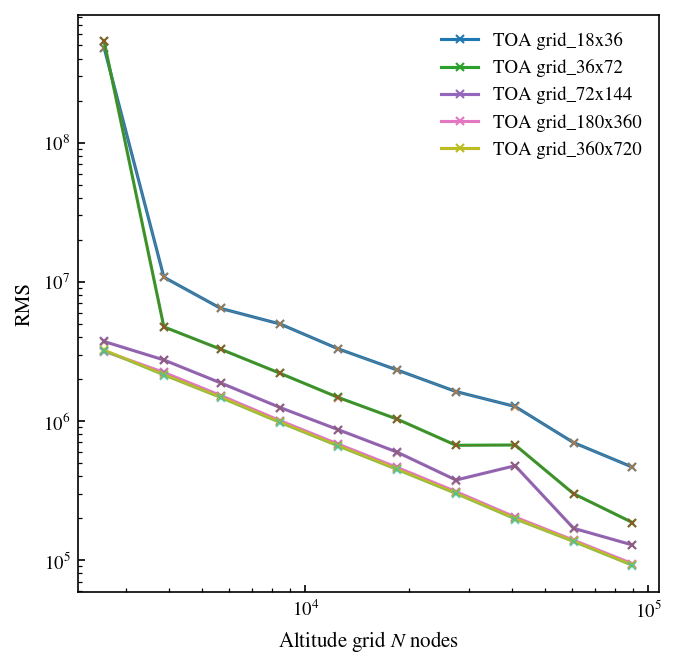

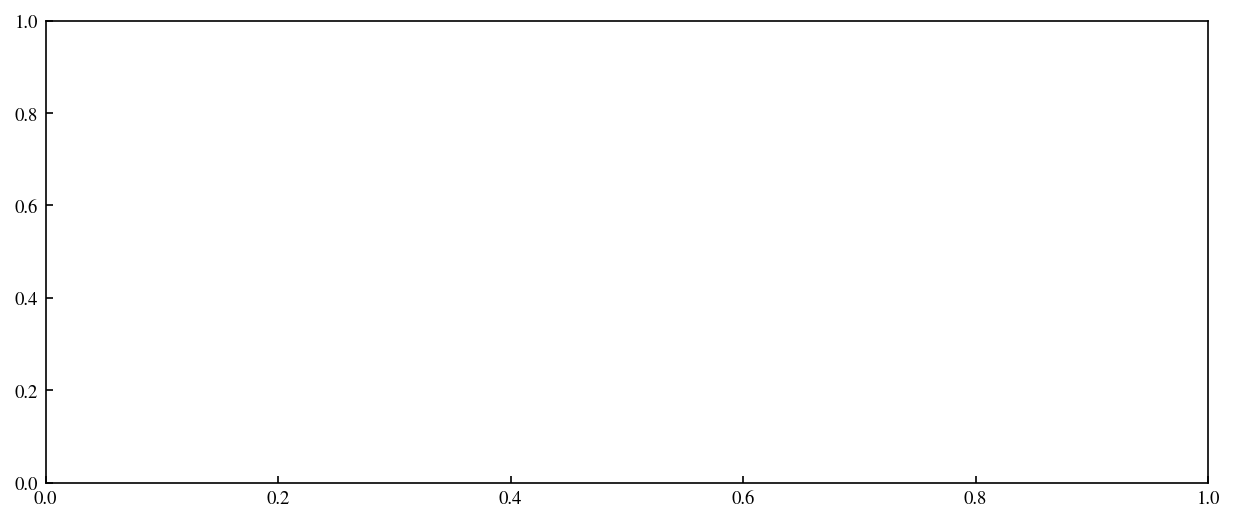

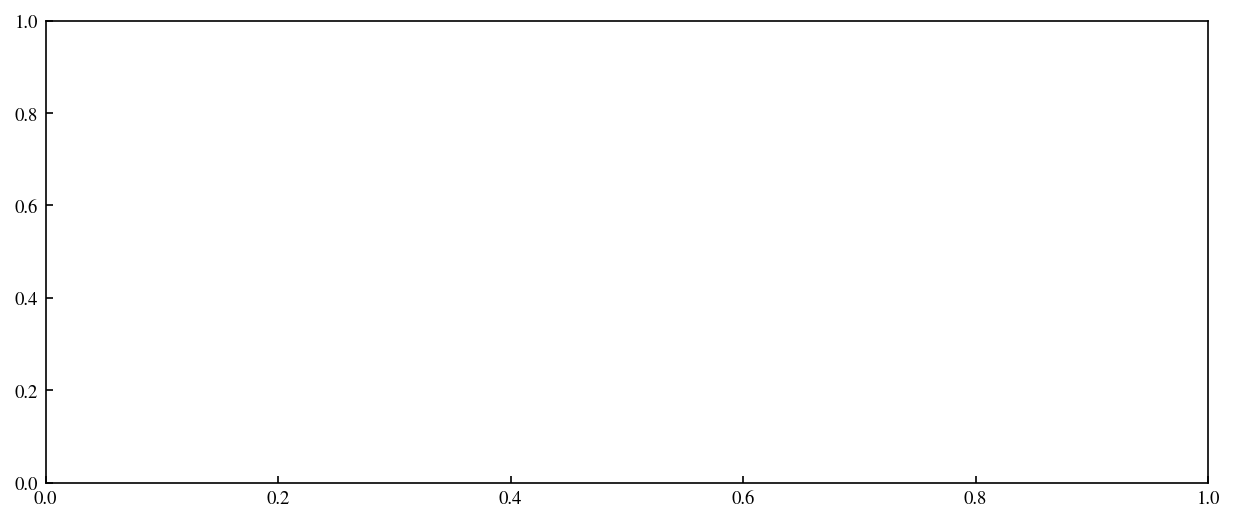

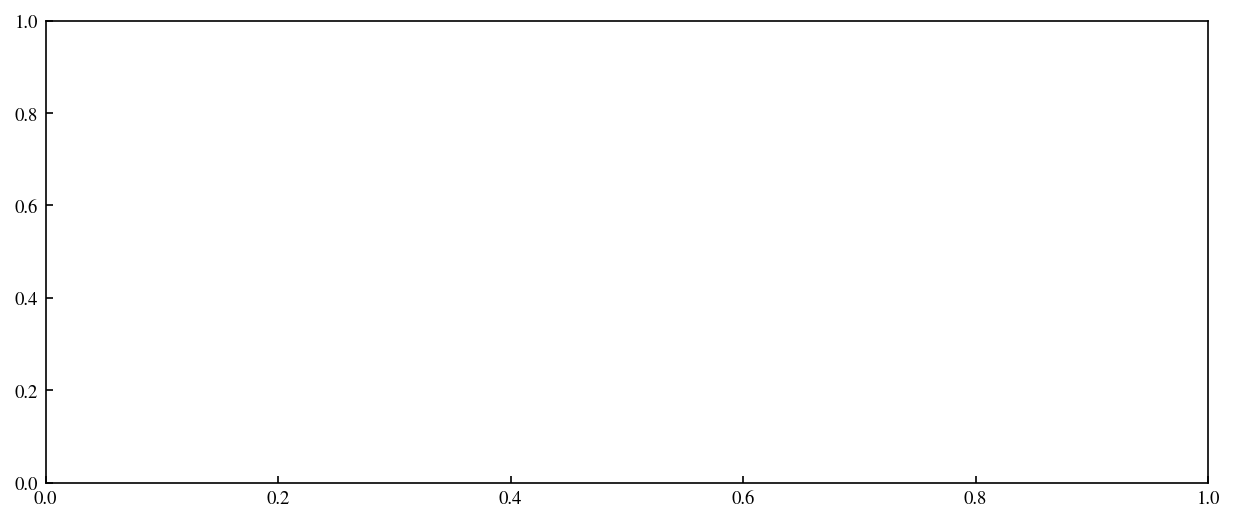

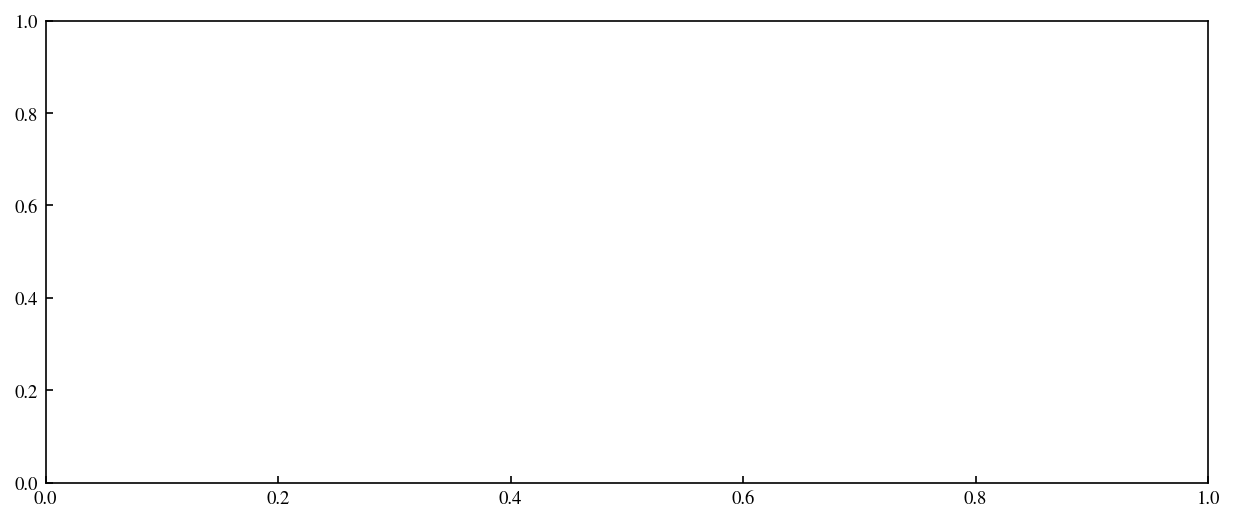

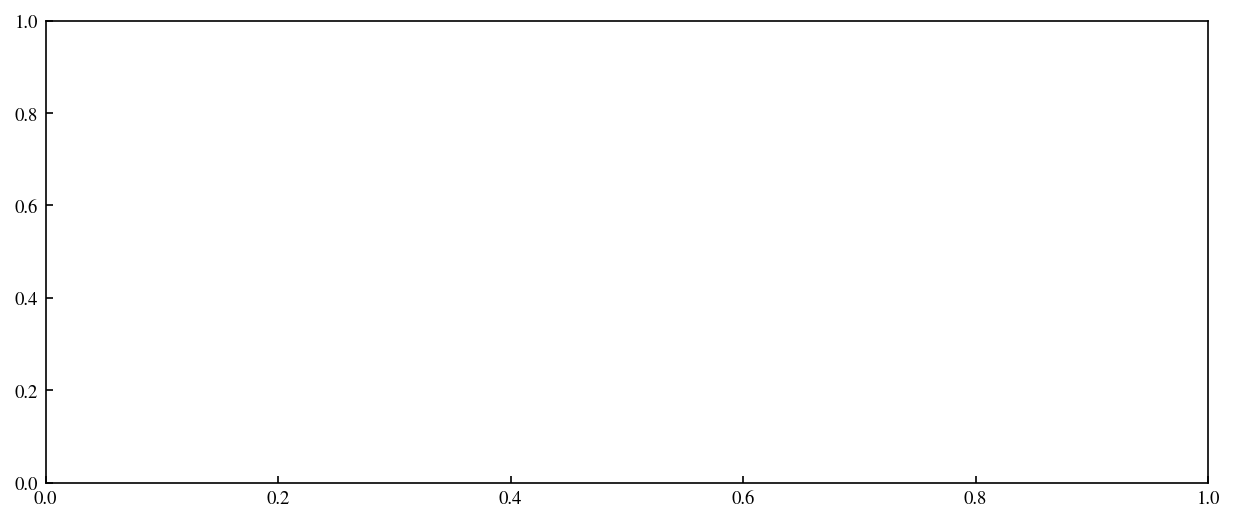

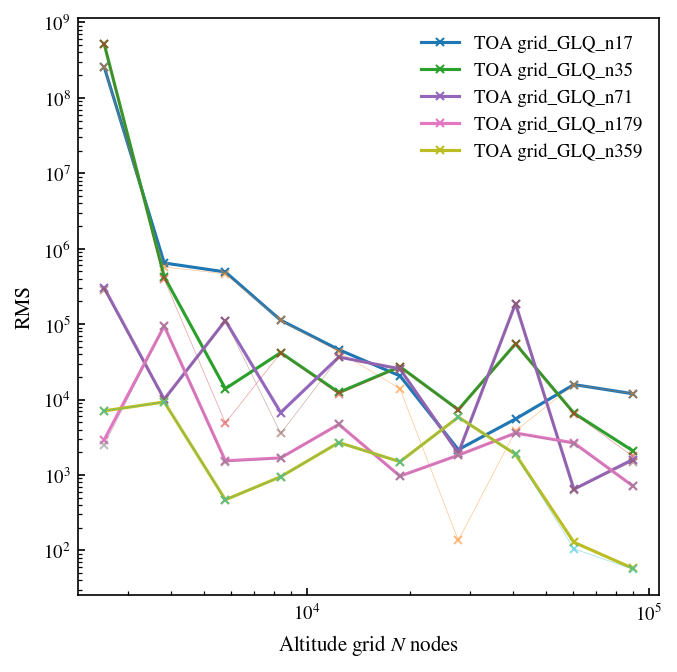

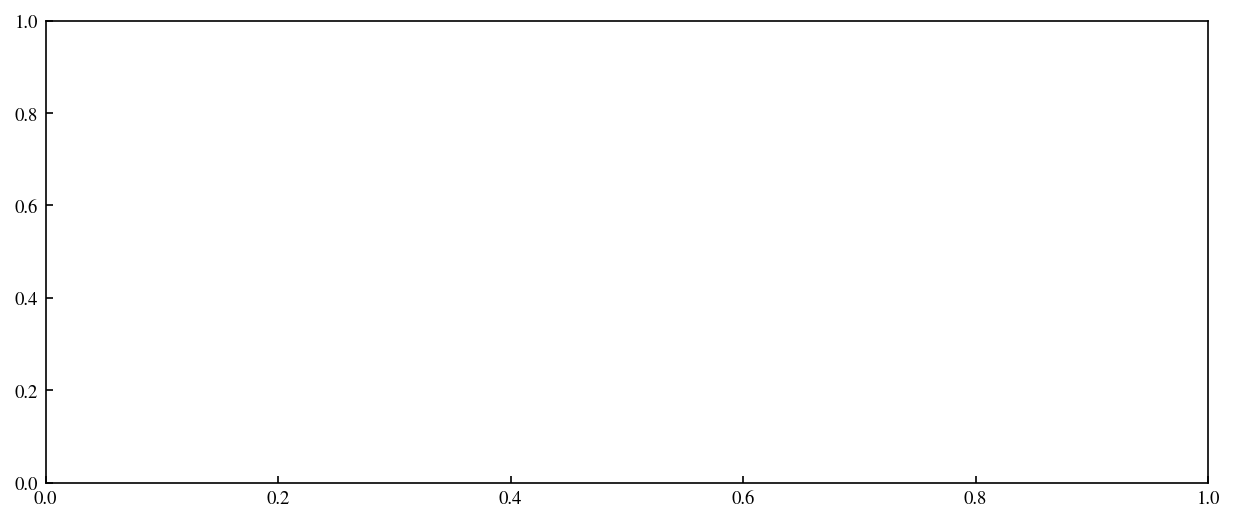

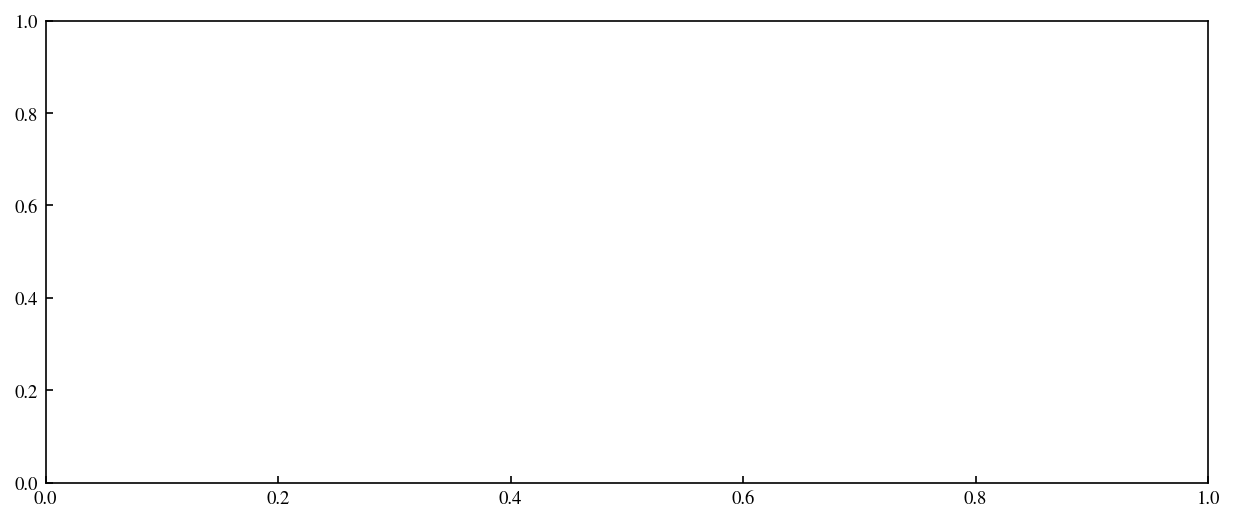

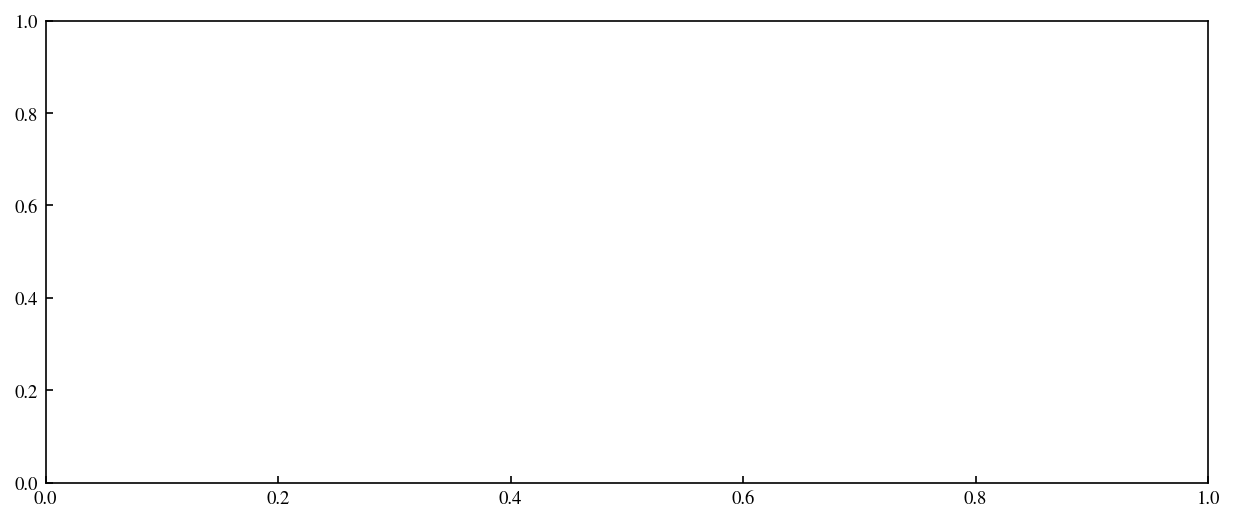

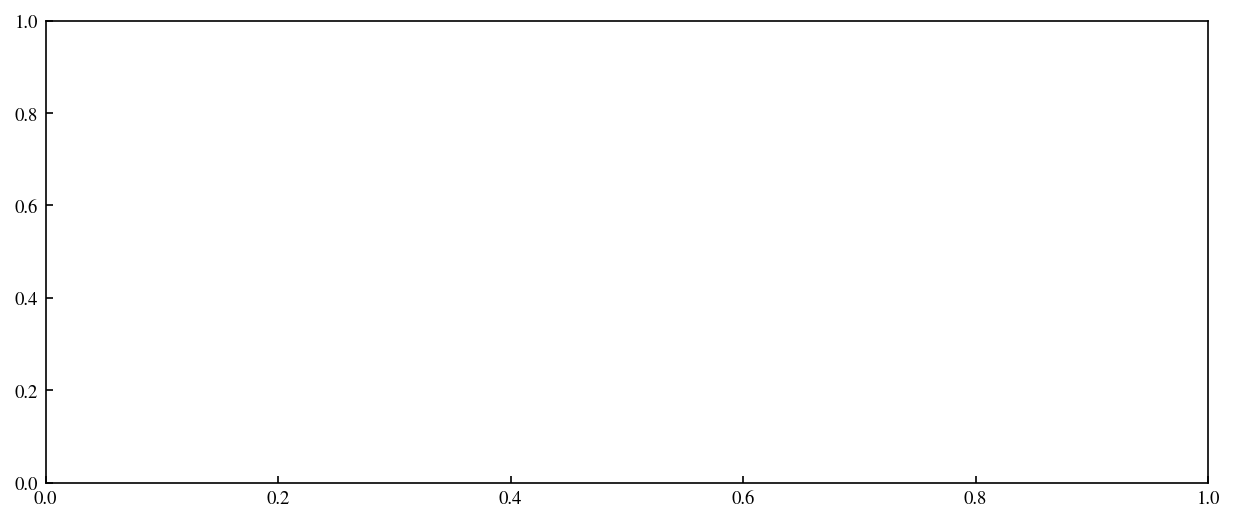

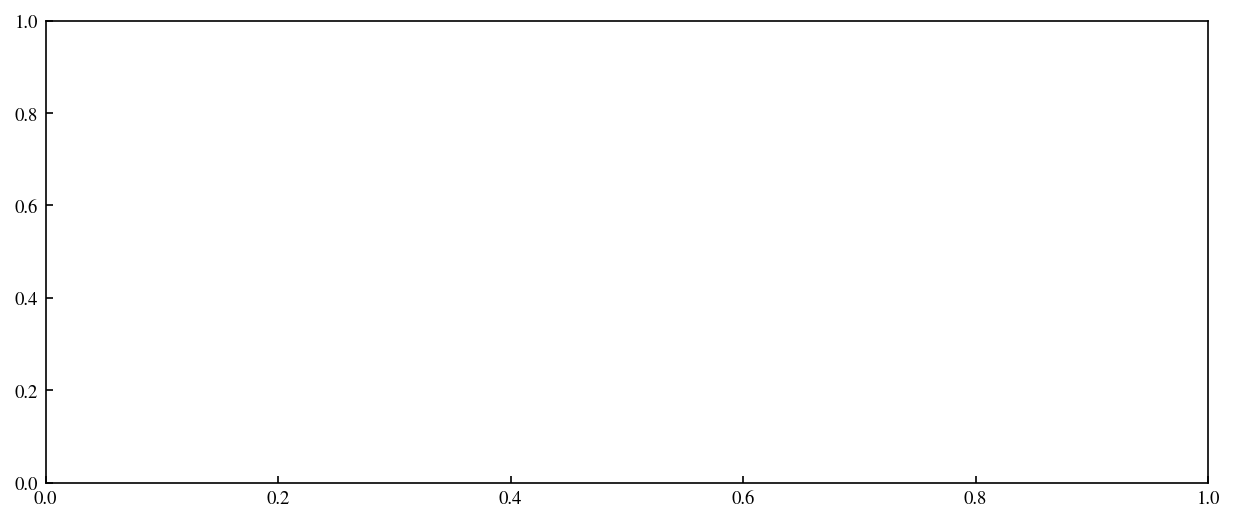

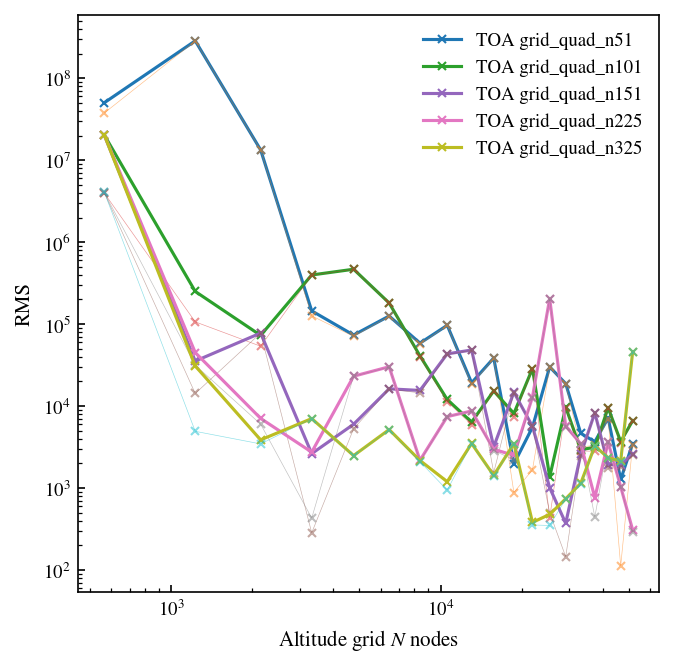

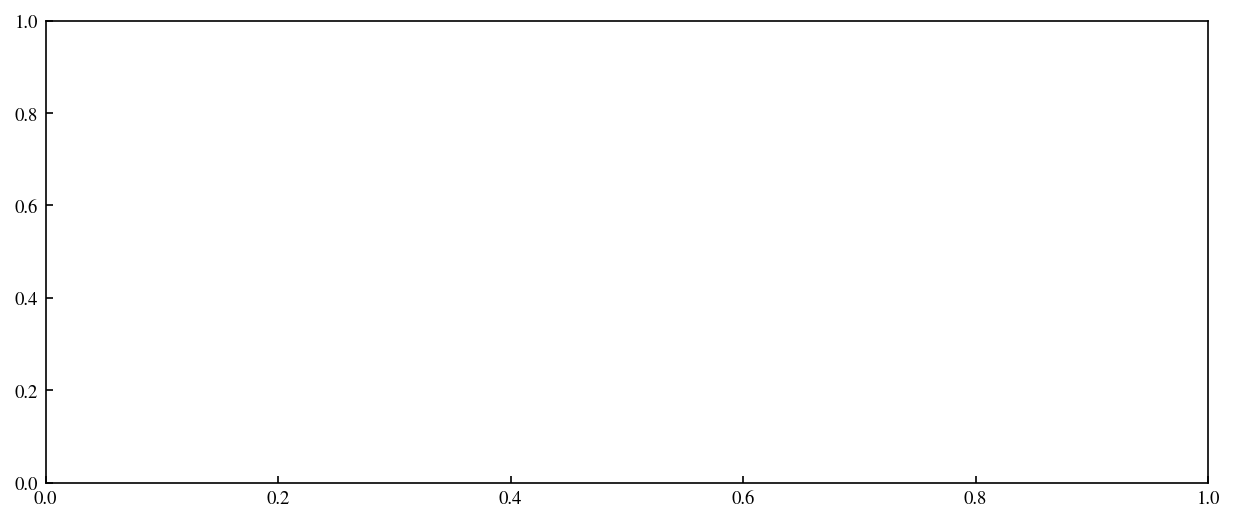

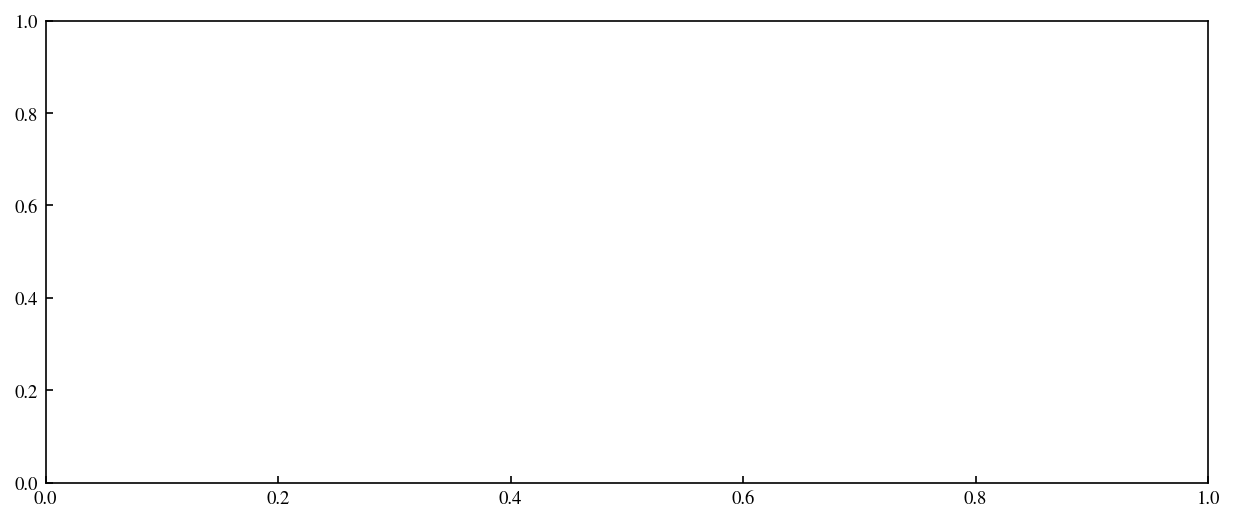

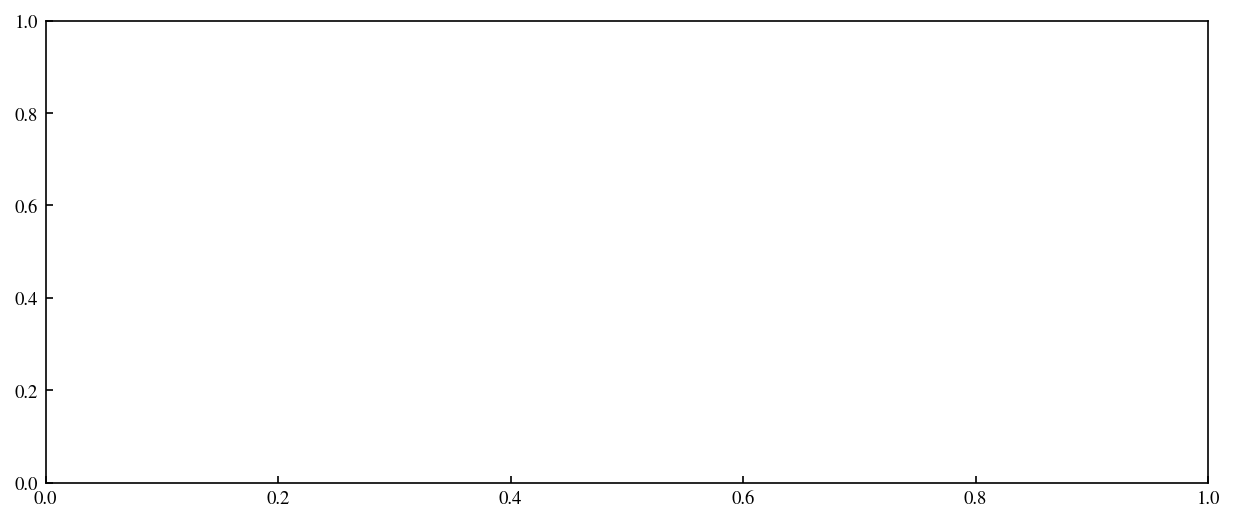

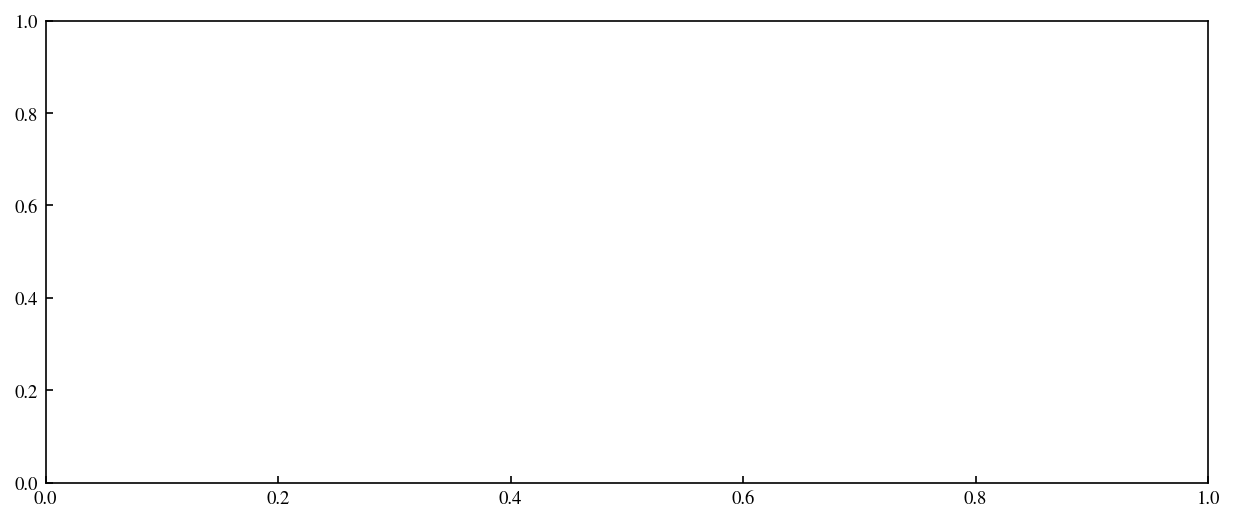

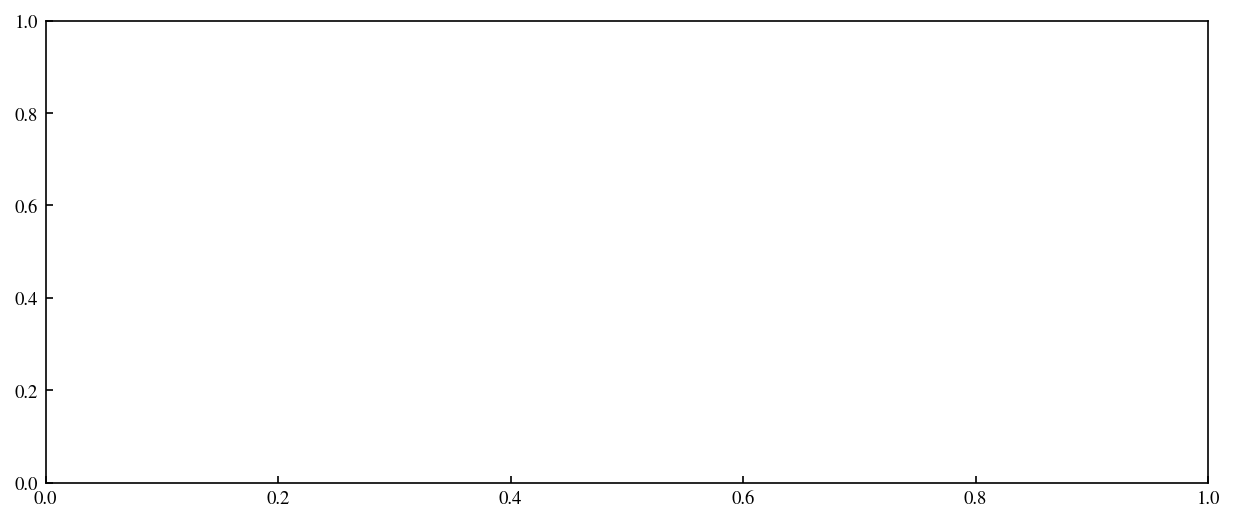

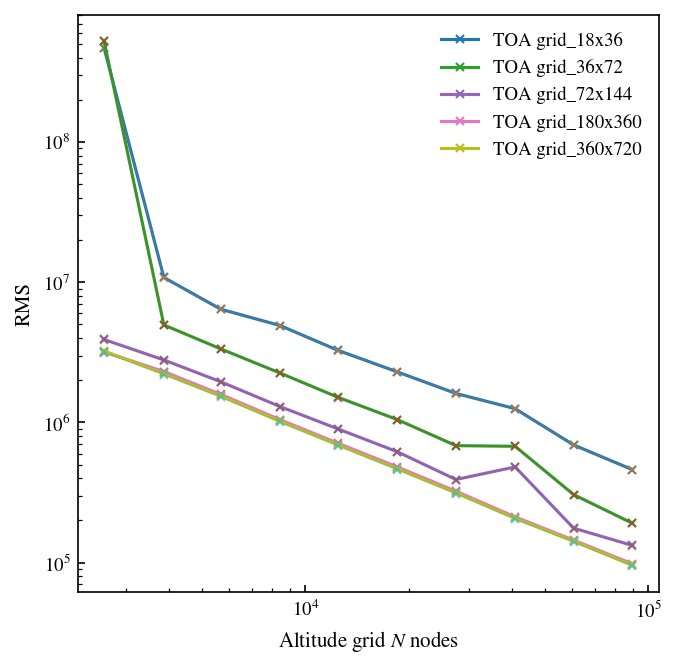

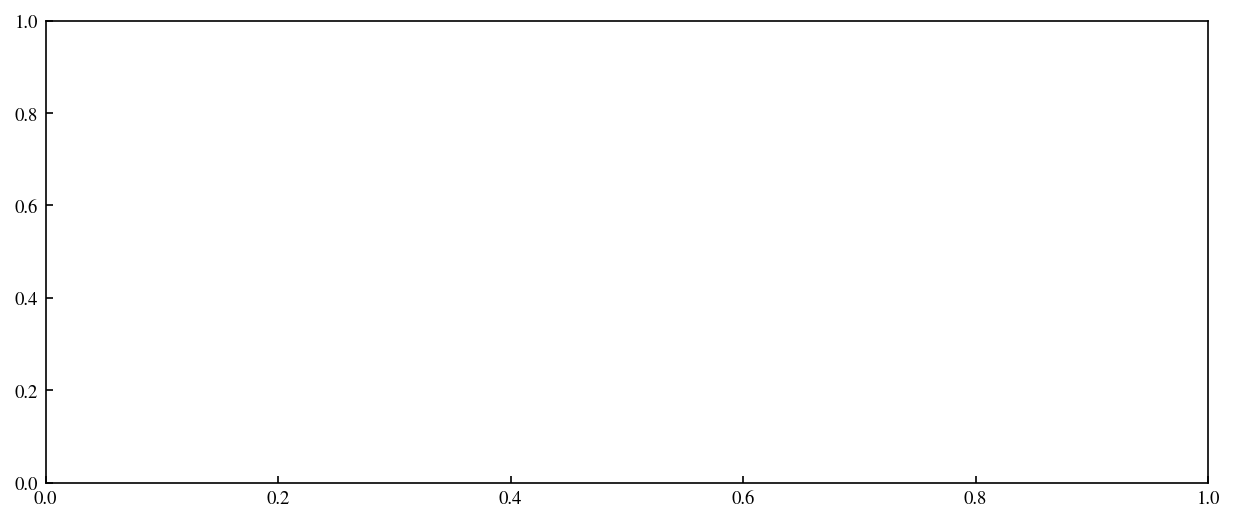

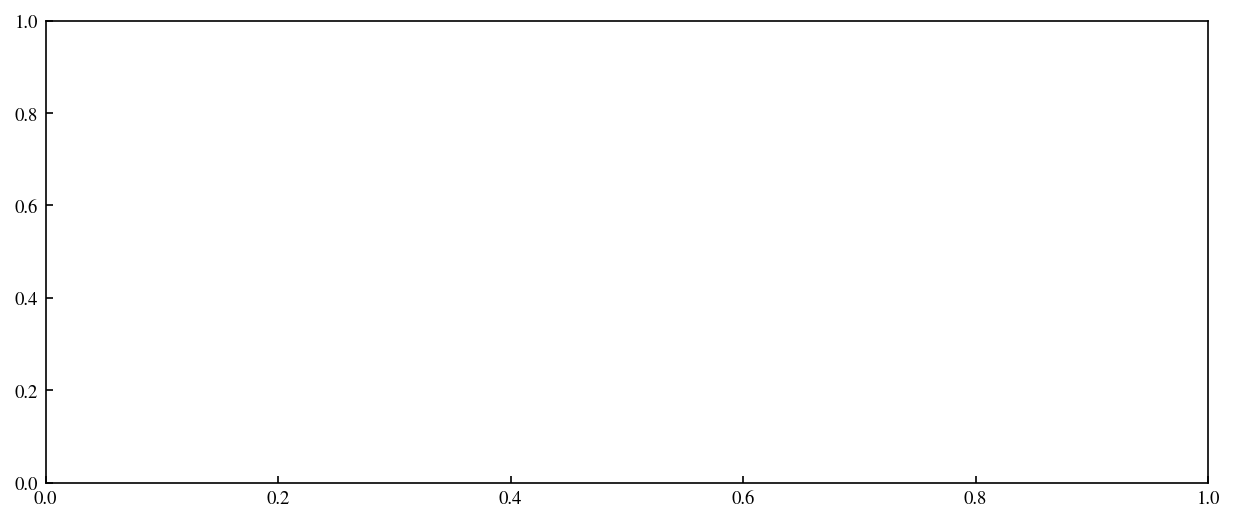

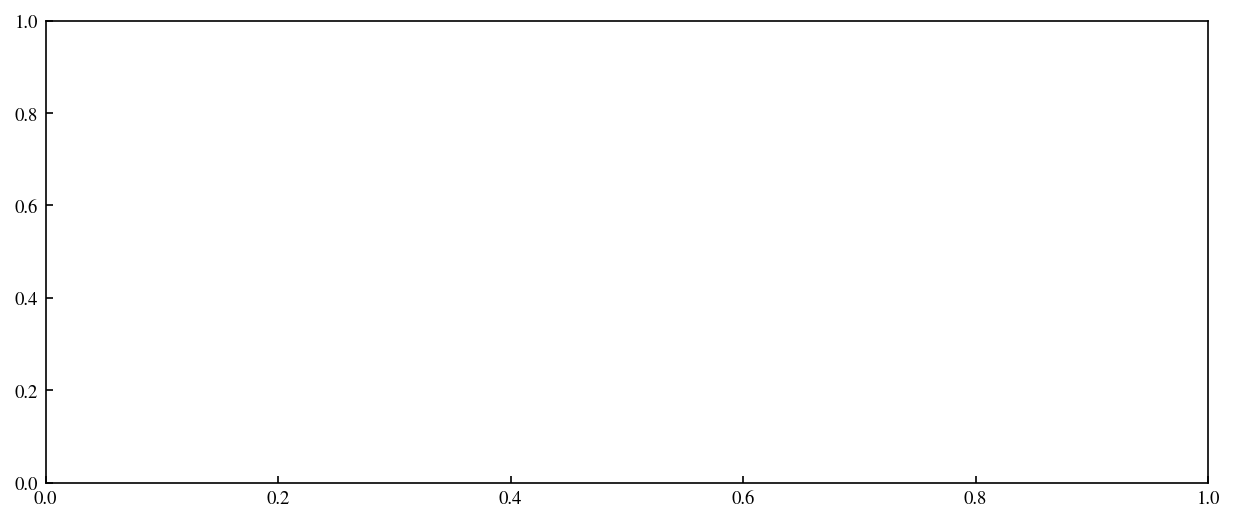

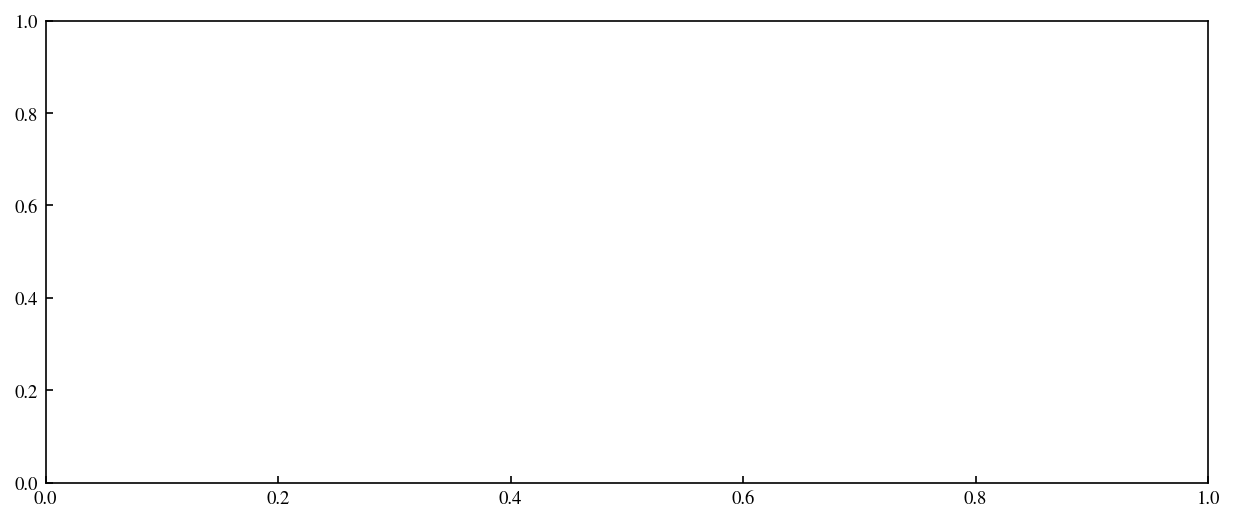

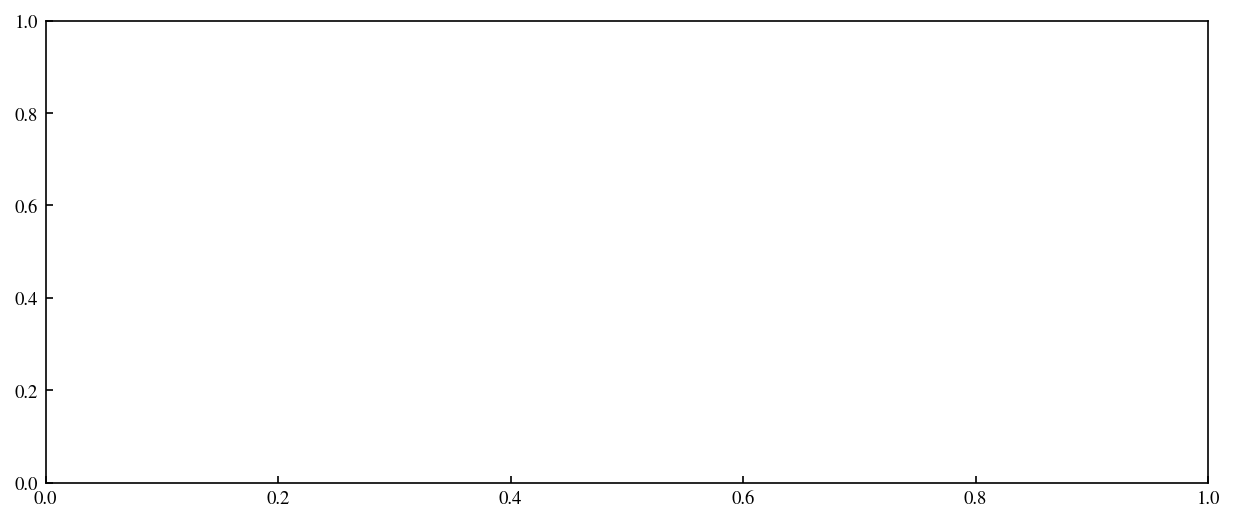

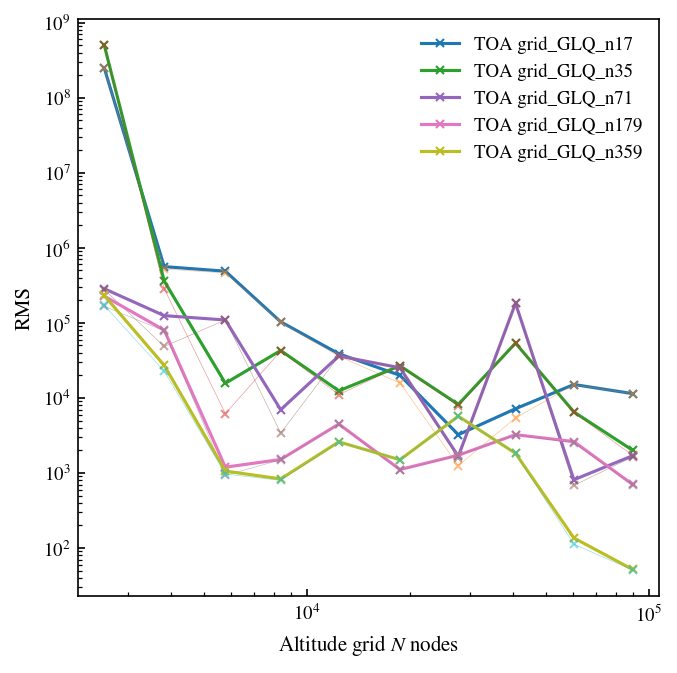

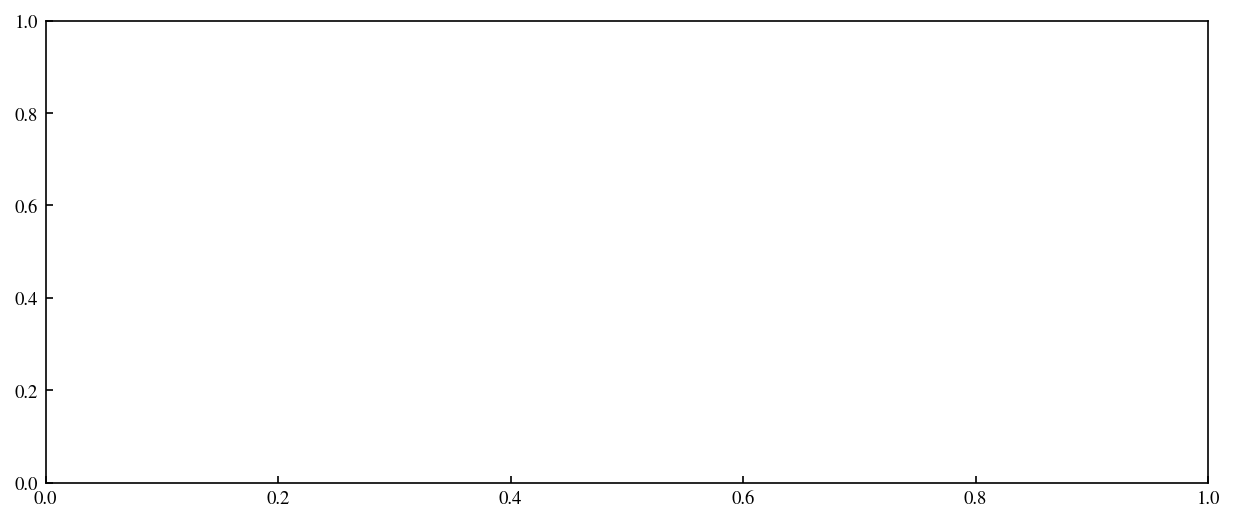

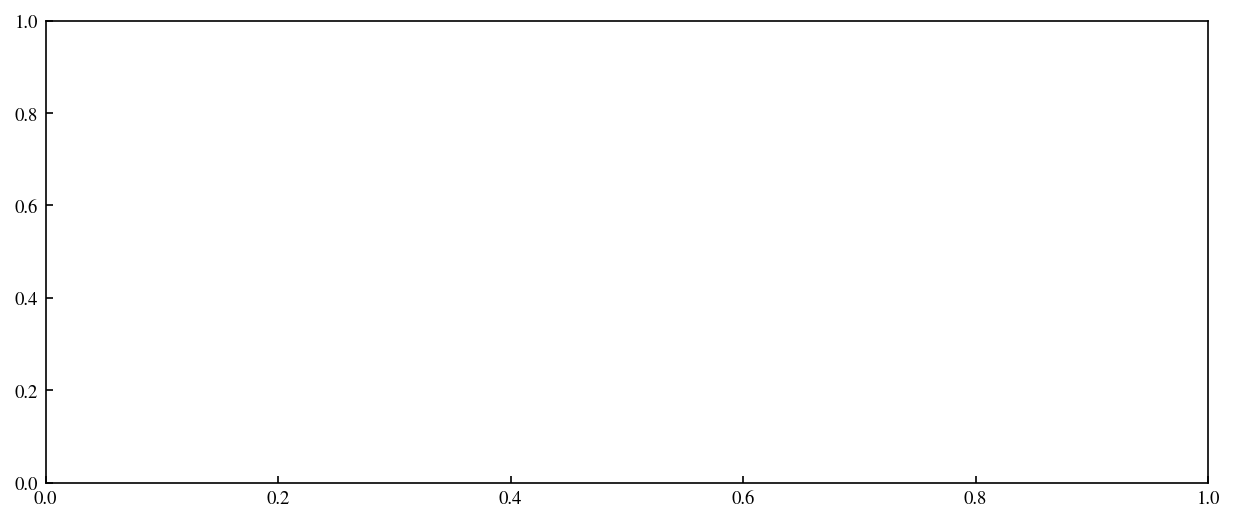

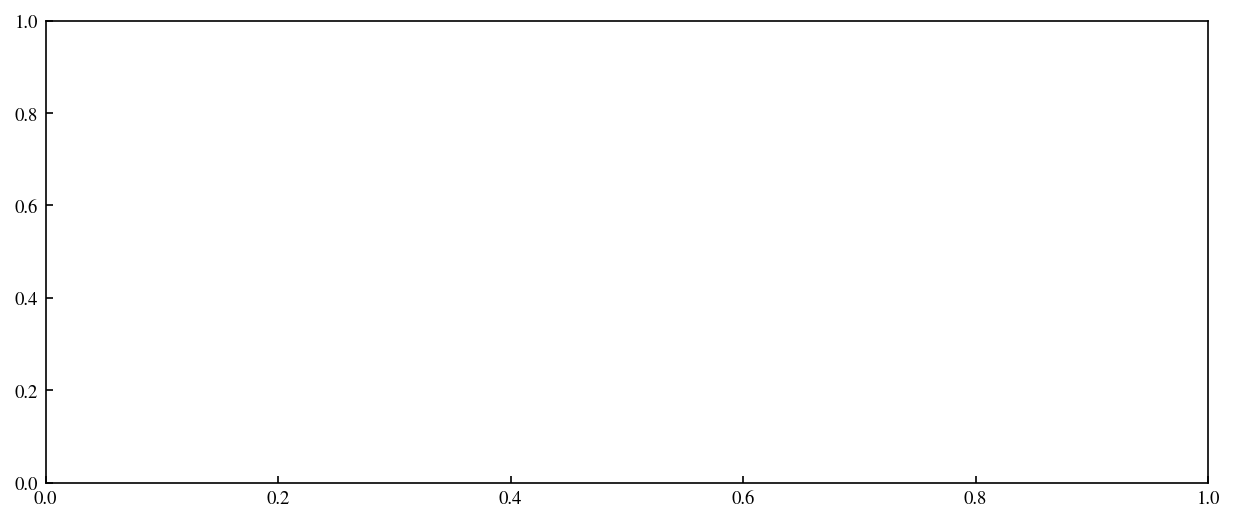

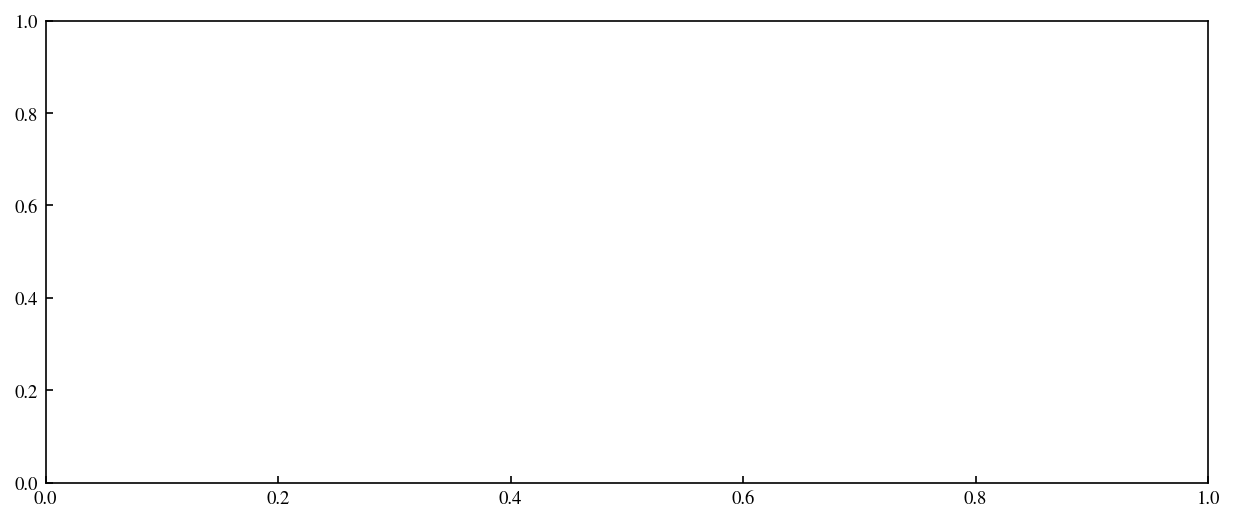

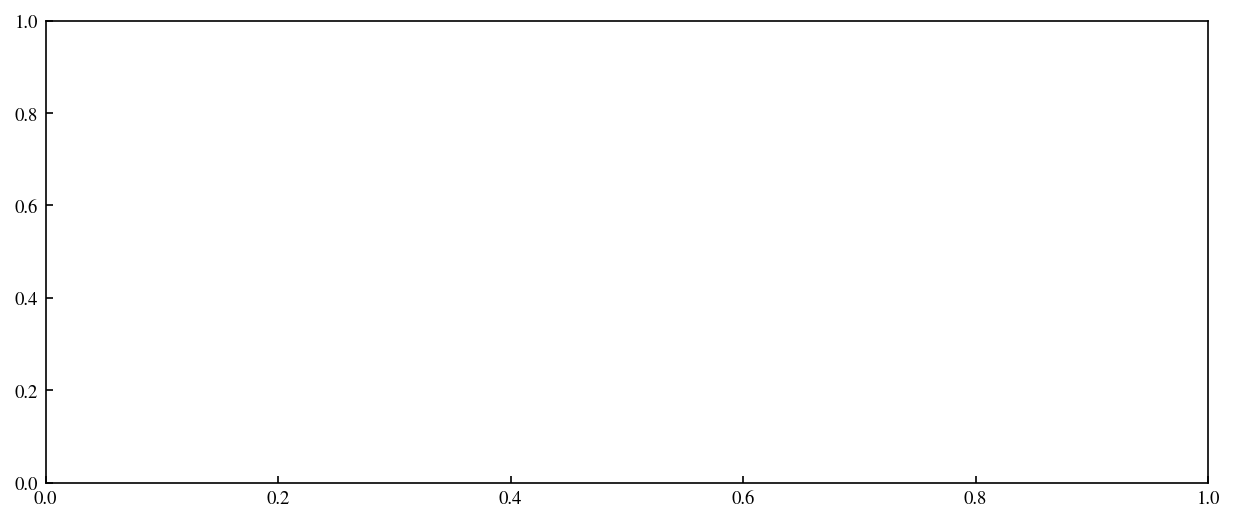

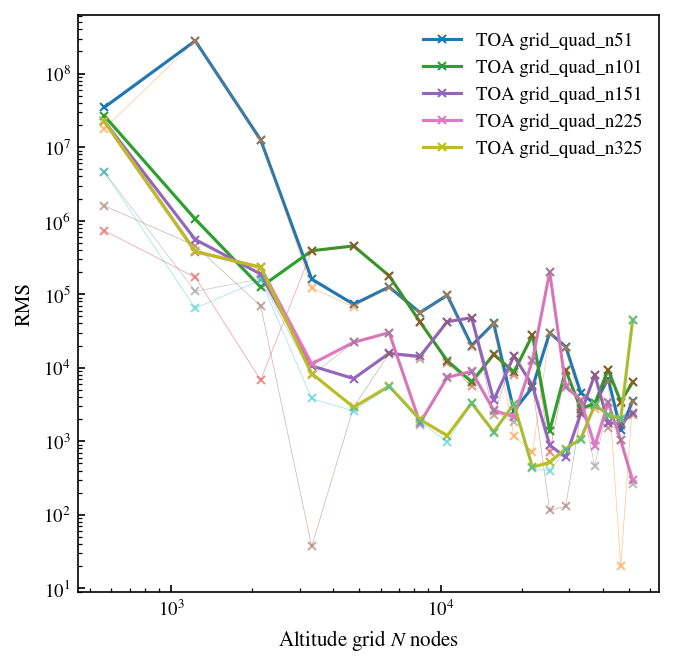

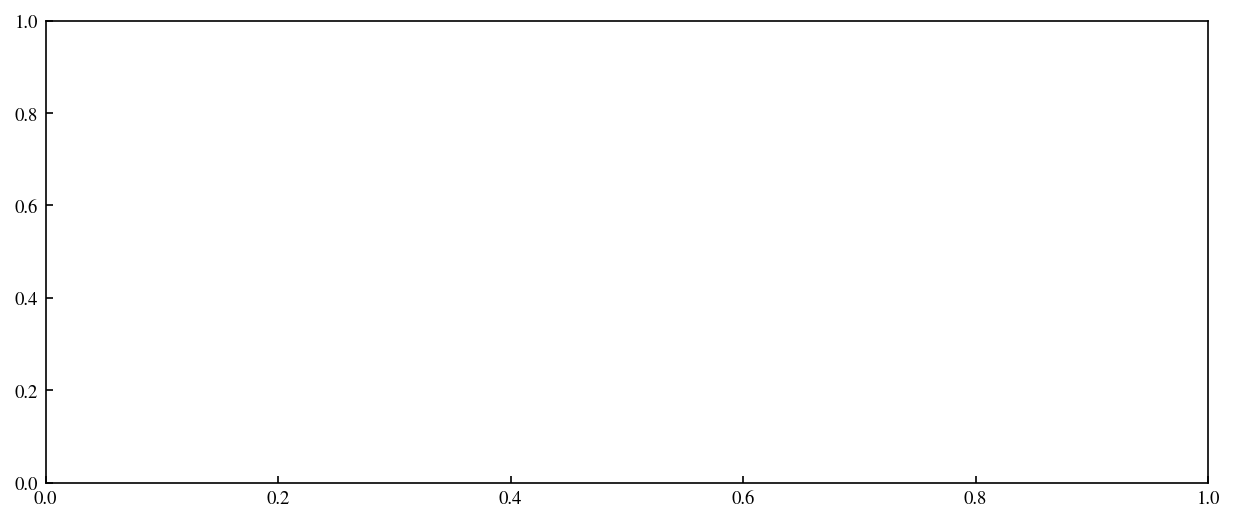

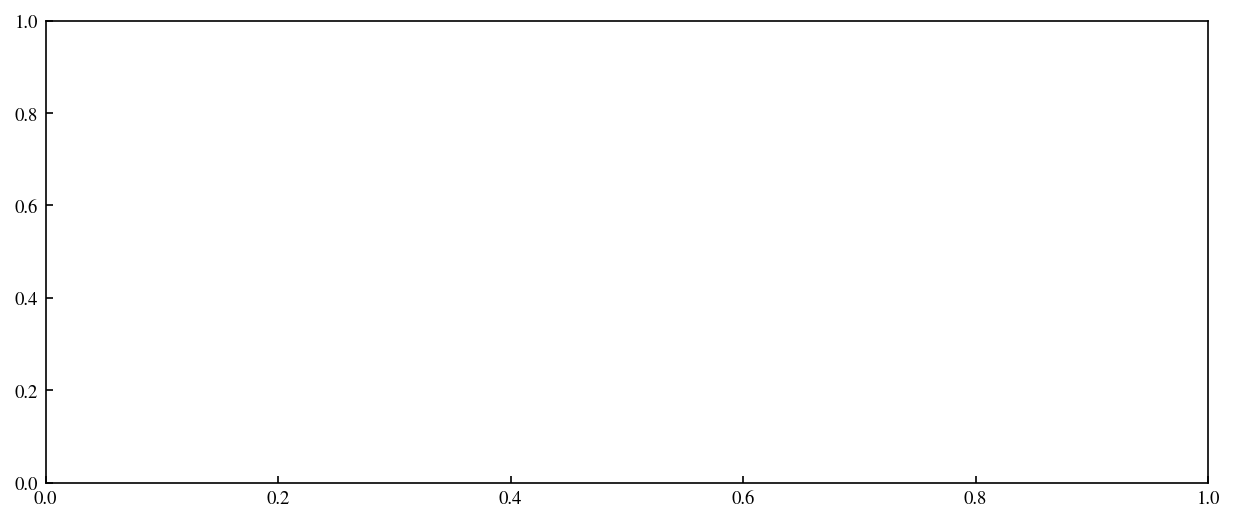

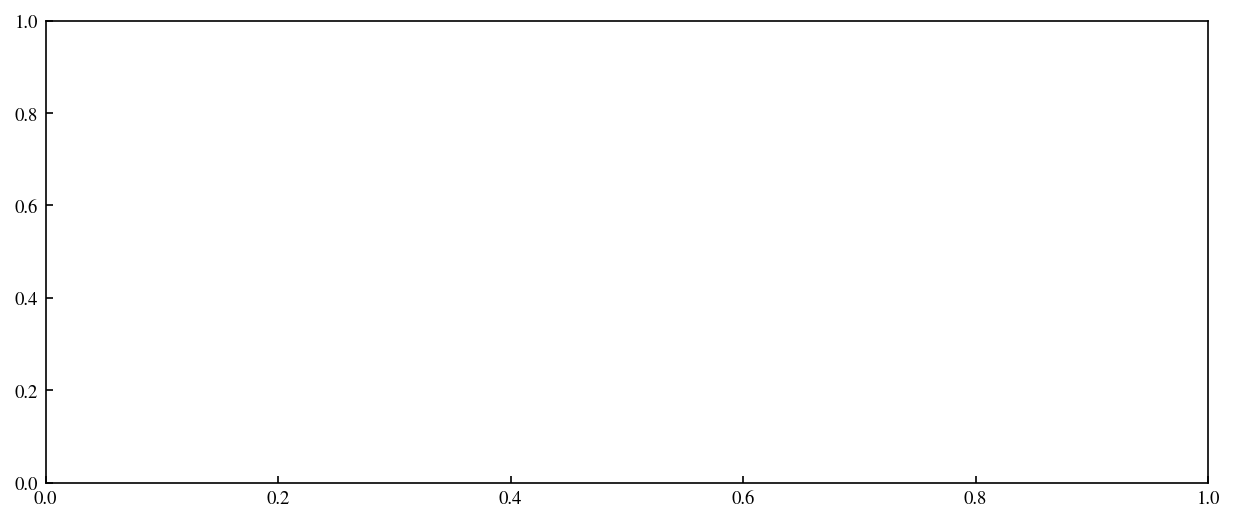

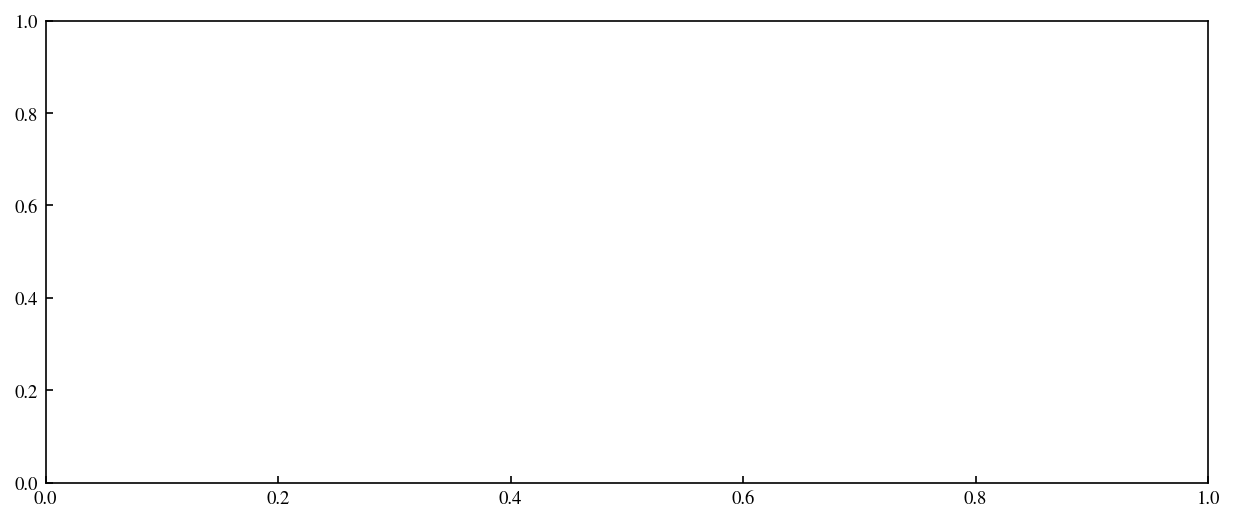

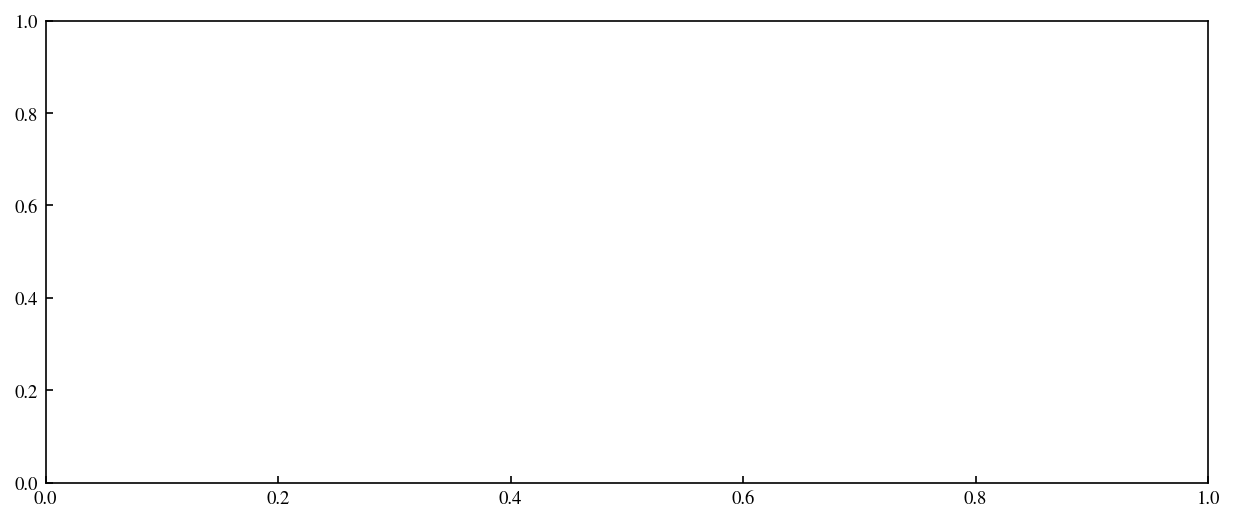

In [2]:
import numpy as np
import sys, os
from SpaceBalls.postproc_EEI_estimation import get_true_EEI_time_series, get_subdir_EEI_truth
from SpaceBalls.radiation_fluxes_preprocessing import mid_day_jd_array_from_jd_interval, get_daily_hist_net_at_altitude, compute_flux_hist_toa, get_r_sun_jd_hist, get_solar_incoming_day_hist, get_EEI_truth_daily_jd_arrays, F_vec_to_Fr, get_toa_grid_from_rad_config
from SpaceBalls.radiation_settings import get_TSI_1AU, radiation_settings_from_EEI_truth_name
from SpaceBalls.sph_meshing import QuadratureGrid, RegularLatLonGrid, Grid
from SpaceBalls.utils import normal_smoother
from SpaceBalls.plotter import Plotter
from SpaceBalls.paths import OUTPUT_DIR, MEDIA_DIR
import matplotlib.pyplot as plt

def glq_n_to_l(n):
    return np.array(np.round(0.25 * (-3 + np.sqrt(1 + 8*n))), dtype=int)

# EEI truths with a/e max. D/O 179
EEI_names = ['EEI_truth_35', 'EEI_truth_3']#, 'EEI_truth_4'] # 'EEI_truth_4'
altitude_km = 800

"""
######################### debug block
EEI_name = "EEI_truth_3"
rad_config = radiation_settings_from_EEI_truth_name(EEI_name)
toa_grid = get_toa_grid_from_rad_config(rad_config, quadrature_order=251)
altitude_grid = QuadratureGrid(800, 225)
all_daily_jd_arrays = get_EEI_truth_daily_jd_arrays(rad_config['jd_interval'])
mid_day_jd_array = mid_day_jd_array_from_jd_interval(rad_config["jd_interval"])
solar_F_alt_hist_ECEF, earth_F_alt_hist_ECEF = get_daily_hist_net_at_altitude(
                            mid_day_jd_array[0], all_daily_jd_arrays[0], rad_config, altitude_grid, sff=False,
                            toa_grid=toa_grid, return_separate=True, compute_solar=False)
np.save(os.path.join(MEDIA_DIR, 'test_earth_F_alt_hist_new.npy'), earth_F_alt_hist_ECEF)
test_hist_og_func = np.load(os.path.join(MEDIA_DIR, 'test_earth_F_alt_hist_og.npy'))
print(f"Max diff: {np.max(np.abs(test_hist_og_func - earth_F_alt_hist_ECEF))}")
a-3 # force code crash
#########################
"""

regular_altitude_grids = [RegularLatLonGrid(altitude_km, n_lat=int(np.round(180*f)), 
                                                         n_lon=int(np.round(360*f)),
                                                         flattening=0) for f in np.logspace(-0.7, 0.5, 15)]
regular_altitude_grids = regular_altitude_grids[:-5]

n_points_glq = np.logspace(np.log10(regular_altitude_grids[0].n_points), 
                           np.log10(regular_altitude_grids[-1].n_points), 
                           len(regular_altitude_grids))
l_glq = glq_n_to_l(n_points_glq)
glq_altitude_grids = [RegularLatLonGrid(altitude_km, lmax=int(l), quad_type='GLQ',
                                       flattening=0) for l in l_glq]

womersley_altitude_grids = [QuadratureGrid(altitude_km, order=o, 
                                           default_womersley=True, 
                                           flattening=0) for o in np.arange(33, 325, 16)]

n_days = 1

for EEI_name in EEI_names:

    rad_config = radiation_settings_from_EEI_truth_name(EEI_name)
    all_daily_jd_arrays = get_EEI_truth_daily_jd_arrays(rad_config['jd_interval'])
    full_jd_array = np.concatenate(all_daily_jd_arrays[:n_days])
    mid_day_jd_array = mid_day_jd_array_from_jd_interval(rad_config["jd_interval"])

    regular_toa_grids = [get_toa_grid_from_rad_config(rad_config, deg_bin_size=d) for d in (10, 5, 2.5, 1, 0.5)]
    n_points_reg_toa_grids = np.array([grid.n_points for grid in regular_toa_grids])
    glq_toa_grids = [get_toa_grid_from_rad_config(rad_config, glq_order=l) for l in glq_n_to_l(n_points_reg_toa_grids)]
    womersley_orders = np.array([51, 101, 151, 225, 325]) # np.round(np.sqrt(2*n_points_reg_toa_grids))
    womersley_toa_grids = [get_toa_grid_from_rad_config(rad_config, quadrature_order=int(l), default_womersley=True) 
                           for l in womersley_orders]

    all_grid_packs = ((regular_toa_grids, regular_altitude_grids), 
                      (glq_toa_grids, glq_altitude_grids),
                      (womersley_toa_grids, womersley_altitude_grids))

    for grid_pack in all_grid_packs:  # regular, GLQ, Womersley
        toa_grids, altitude_grids = grid_pack
        fig_conv_earth, ax_conv_earth = plt.subplots(figsize=(5, 5))
                
        for day_idx in range(n_days):
            day_jd_array = all_daily_jd_arrays[day_idx]
            mid_day_jd = mid_day_jd_array[day_idx]
            out_dir = os.path.join(MEDIA_DIR, 'conservation_convergence', EEI_name, 'day_' + str(day_idx))
            os.makedirs(out_dir, exist_ok=True)

            #fig_solar, ax_solar = plt.subplots(figsize=(10,4))
            
            for toa_idx, toa_grid in enumerate(toa_grids):

                fig_earth, ax_earth = plt.subplots(figsize=(10,4))

                first_toa_idx = (toa_idx==0)
                toa_earth_fname = os.path.join(out_dir, 'integrated_earth_toa_hist_'+toa_grid.grid_name+'.npy')
                toa_solar_fname = os.path.join(out_dir, 'integrated_solar_toa_hist_'+toa_grid.grid_name+'.npy')

                toa_earth = np.load(toa_earth_fname)
                toa_solar = np.load(toa_solar_fname)
                #ax_earth.plot(Plotter.jd_to_datetime(day_jd_array), toa_earth, lw=2, label='TOA')
                #ax_solar.plot(Plotter.jd_to_datetime(day_jd_array), toa_solar, lw=2, label='TOA ' + toa_grid.grid_name)

                bias_array = []
                rms_array = []
                for altitude_grid in altitude_grids:
                    fname_earth = os.path.join(out_dir, 'integrated_earth_'+str(altitude_km)+'_hist_'+altitude_grid.grid_name + 'from_toa_' + toa_grid.grid_name + '.npy')
                    earth = np.load(fname_earth)
                    error = earth - toa_earth
                    bias_array.append(np.mean(error))
                    rms_array.append(np.sqrt(np.mean(error**2)))

                    if first_toa_idx:
                        fname_solar = os.path.join(out_dir, 'integrated_solar_'+str(altitude_km)+'_hist_'+altitude_grid.grid_name + '.npy')
                        solar = np.load(fname_solar)
                        #ax_solar.plot(Plotter.jd_to_datetime(day_jd_array), solar, label='Altitude ' + altitude_grid.grid_name)



                n_points_array = [grid.n_points for grid in altitude_grids]
                ax_conv_earth.loglog(n_points_array, rms_array, label='TOA ' + toa_grid.grid_name, marker='x')
                ax_conv_earth.loglog(n_points_array, np.abs(bias_array),  marker='x', alpha=0.5, lw=0.3)

            ax_conv_earth.legend()
            ax_conv_earth.set_xlabel('Altitude grid $N$ nodes')
            ax_conv_earth.set_ylabel('RMS')

                    #ax_earth.plot(Plotter.jd_to_datetime(day_jd_array), earth, linestyle='--', label='Altitude ' + altitude_grid.grid_name)



                # ax_earth.legend()
                # ax_earth.set_title(EEI_name + ' - TOA ' + toa_grid.grid_name)
                # Plotter.format_time_labels(ax_earth)

            # ax_solar.legend()
            # ax_solar.set_title(EEI_name)
            # Plotter.format_time_labels(ax_solar)